# Labjournaal BM
## General

**Name:** Pieter Jelle Biesheuvel en Bregje

**Title of the experiment:** Bepaling van de constante van Boltzmann aan de hand van een diode 

**Starting date:** 10 November 2026 

**Expected enddate:** 23 November 2026

**Desired accuracy:** 10^-24 J/K

In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:** De bepaling van de constante van Boltzmann kan worden gedaan met een diode. Het is echter zo dat de stroom die door de diode gaat niet direct kan worden gemeten. Dat komt omdat de weerstand van de stroommeter niet verwaarloosbaar is bij het meten van de diode. Daarom moet de stroom door de diode indirect worden gemeten. <br>
**Theory:** Om de stroomsterkte van de diode te krijgen geldt de volgende formule: $$I_D = I_0\left(e^{\frac{-qU_D}{nk_BT}}-1\right)$$ Waar $q = -1,602 \times 10^{-19}$ Coulomb, $n = 2.0$, $T$=293 Kelvin de temperatuur in Kelvin en $I_0$ de sperstroom die moet worden gefit. <br><br>De stroomsterkte door de diode wordt gegeven door: $$I_D = \frac{U_{R_1}}{R_1}$$ De spanning over de diode wordt gegeven door:$$U_D = \frac{R_3}{R_2+R_3}\,U_{bron} - U_{R_1}$$ Waar de weerstanden hetvolgende bedragen: $$R_1 = 10000,3 Ω $$ $$R_2 = 992,0 Ω $$ $$R_3 = 325,15 Ω $$ <br> Dit geldt alleen als: $R_3 \ll R_1 + R_D$ <br>
De onzekerheid wordt gegeven door: $$u(k_B) = k_B\sqrt{\left(\frac{u_{fit}(k_B)}{k_B}\right)^2+\left(\frac{u(n)}{n}\right)^2+\left(\frac{u(T)}{T}\right)^2}$$
$u_{fit}$ wordt gegeven door de fitfunctie. <br>
$u_n = {0,1}$

<br><br>
**Independent variable:**  Spanning <br>
**Dependent variable:**  Stroomsterkte<br>
**Controlled variablen:**  Temperatuur<br>
**Measurement instruments \& Settings:**  <br>
- Dynatek D9100
- Thurlby 1905a
- Thermometer
<br><br>
**Procedure:**  <br>
- Meten van de drie weerstanden met de 5,5 DMM meter
- Opbouwen van de opstelling
- Aansluiten van de 5,5 DMM meter op de bronspanning
- Aansluiten van de 3,5 DMM meter om $U_{R_1}$ te meten
- De bronspanning instellen op 6,0 volt en dan de $U_{R_1}$ en de bronspanning meten
- Spanning telkens met 0,25 volt verminderen tot 0 volt.
- Temperatuur meten
- Met een functiefit de constante van Boltzmann berekenen
<br>
**Setup(drawing or picture):**  <img src="Figures/BM/BMopstelling.png" width="400">
**Notes:**  
**About accuracy:**  


# Execution

In [38]:
# Inladen data
with open("/Users/pieterjellebiesheuvel/Documents/TN/1ejaar/Q2/Bepaling constante van Boltzmann/metingen.csv") as f:
    regels_metingen = f.read().replace(",", ".").splitlines()
gemeten_U_bron, gemeten_U_R1 = np.loadtxt(regels_metingen, delimiter=";", skiprows=1, usecols=(1, 2), unpack=True)

weerstanden_bestands_naam="/Users/pieterjellebiesheuvel/Documents/TN/1ejaar/Q2/Bepaling constante van Boltzmann/weerstandBM.csv"
with open(weerstanden_bestands_naam) as f:
    regels_weerstanden = f.read().replace(",", ".").splitlines()

np_regels_weerstanden = np.loadtxt(regels_weerstanden, delimiter=";", skiprows=2)
R_een=np_regels_weerstanden[6,2] #10k ohm
R_twee=np_regels_weerstanden[4,2] #1000 ohm
R_drie=np_regels_weerstanden[2,2] #330 ohm

**Observations:**  
- ${R_3}$ en ${R_1}$ verhouden zich als volgt: $\frac{R_3}{R_1} = \frac{325{,}15}{10000{,}3} \approx 0{,}033$
- $R_d$ is ongeveer 1000 ohm
- $R_3$ is niet verwaarloosbaar

**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**  
Uit de gemeten bronspanning $U_{bron}$ en de spanning over de weerstand $U_{R_1}$ worden de stroomsterkte door en de spanning over de diode berekend met $I_D = \frac{U_{R_1}}{R_1}$ en $U_D = \frac{R_3}{R_2+R_3}\,U_{bron} - U_{R_1}$. Deze berekende waardes zijn door een functie_fit gebruik met de formule $$I_D = I_0\left(e^{\frac{-qU_D}{nk_BT}}-1\right)$$ om de constante van Boltzmann te berekenen.

In [4]:
#Functies:
def I_van_R_een(U_R_1):  #en daarbij van diode
    return U_R_1/R_een
def U_van_Diode(U_bron,U_R_1):
    return (U_bron*R_drie)/(R_twee+R_drie) - U_R_1
I_D = I_van_R_een(gemeten_U_R1)
U_D = U_van_Diode(gemeten_U_bron,gemeten_U_R1)

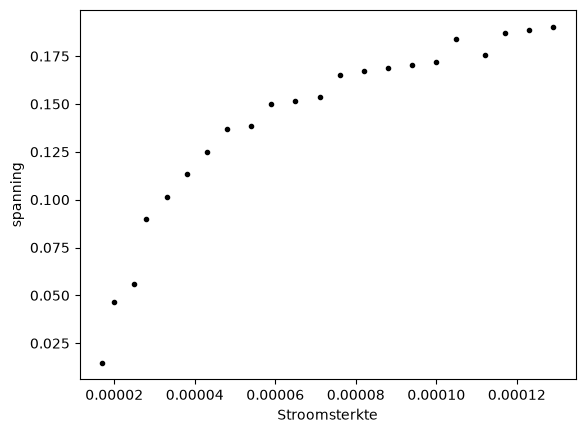

In [5]:
#Eerste plot:
plt.figure()
plt.plot(I_D[U_D>0],U_D[U_D>0],".k")
plt.xlabel("Stroomsterkte")
plt.ylabel("spanning")
plt.show()

In [6]:
#Data processing and analysis:
def onzekerheid_driehalf_voltage(meetpunt: int):
    return 0.007 * meetpunt + 0.01
def onzekerheid_vijfhalf_voltage(meetpunt: int):
    return meetpunt *0.00015 
def onzekerheid_vijfhalf_weerstand(R):
    return 0.0002 * R
uncer_U_Bron=onzekerheid_vijfhalf_voltage(gemeten_U_bron)
uncer_U_R1=onzekerheid_driehalf_voltage(gemeten_U_R1)


uncer_R1=onzekerheid_vijfhalf_weerstand(R_een)
uncer_R2=onzekerheid_vijfhalf_weerstand(R_twee)
uncer_R3=onzekerheid_vijfhalf_weerstand(R_drie)

uncer_U_D = np.sqrt(uncer_U_Bron**2 + uncer_U_R1**2)
uncer_I_D = I_D * np.sqrt((uncer_U_R1 / gemeten_U_R1)**2 + (uncer_R1 / R_een)**2)

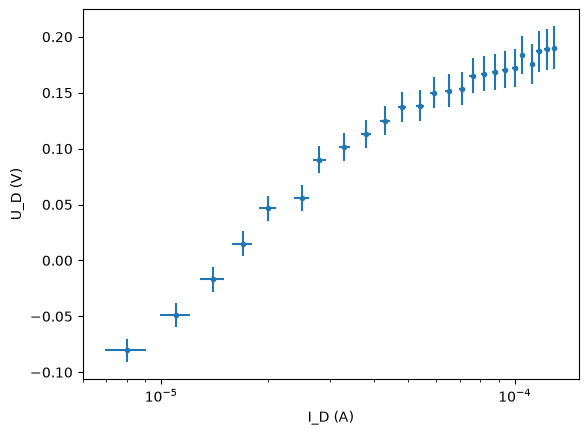

In [27]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
plt.figure()
plt.errorbar(I_D, U_D, xerr=uncer_I_D, yerr=uncer_U_D, fmt=".")
plt.xscale("log")
plt.ylabel("U_D (V)")
plt.xlabel("I_D (A)")
plt.show()

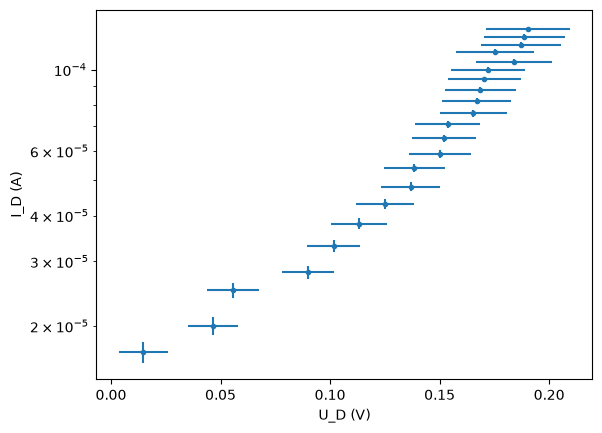

In [8]:
#Er zijn punten waar de spanning kleiner is dan 0. Dit is niet in overeenstemming met het model. Daarom filteren we ze eruit
selectie = U_D > 0
plt.figure()
plt.errorbar(U_D[selectie], I_D[selectie], xerr=uncer_U_D[selectie], yerr=uncer_I_D[selectie], fmt=".")
plt.yscale("log")
plt.xlabel("U_D (V)")
plt.ylabel("I_D (A)")
plt.show()

Constante van Bolzmann: 1.9741509857280604e-23 ± 1.8836506939521952e-24


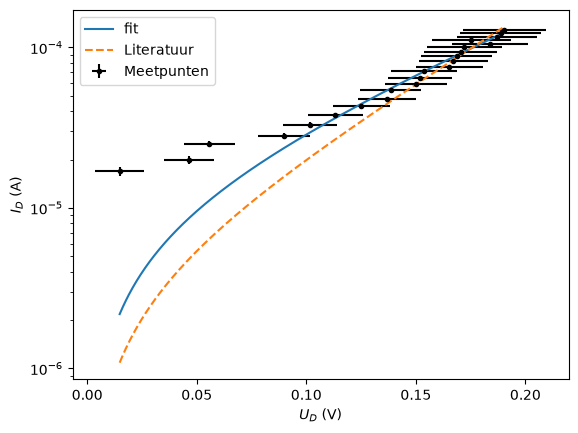

In [17]:
def I_diode(VD,INul,Kb):
    n=2
    T=293
    q=-1.602*(10**-19)
    return INul * (((np.e)**(-q*VD/(n*Kb*T)))-1)
popt,pcov = curve_fit(I_diode, U_D[selectie], I_D[selectie], p0=[10**-5, 10**-23])
print(f"Constante van Bolzmann: {popt[1]} ± {np.sqrt(np.diag(pcov)[1])}")

k_B_literatuur = 1.380649 *(10**-23)

def I_diode_literatuur(VD, INul):
    return I_diode(VD, INul, k_B_literatuur)

popt_lit, pcov_lit = curve_fit(I_diode_literatuur, U_D[selectie], I_D[selectie], p0=[10**-6])

U_model = np.linspace(U_D[selectie].min(), U_D[selectie].max(), 500)

plt.figure()
plt.errorbar(U_D[selectie], I_D[selectie], xerr=uncer_U_D[selectie], yerr=uncer_I_D[selectie],
             fmt=".k", label="Meetpunten")
plt.plot(U_model, I_diode(U_model, *popt), "-", label="fit")
plt.plot(U_model, I_diode_literatuur(U_model, *popt_lit), "--", label=f"Literatuur")
plt.yscale("log")
plt.xlabel("$U_D$ (V)")
plt.ylabel("$I_D$ (A)")
plt.legend()
plt.show()

**Describing the pattern in the processed data:**  
- De stroom neemt exponentieel toe met de spanning
- Vanaf ongeveer 0,1 Volt liggen de punten op de functie

In [37]:
n = 2.0
u_n = 0.1
T = 293
u_T = 4

k_B = popt[1]
u_fit = np.sqrt(np.diag(pcov)[1])
u_k_B = k_B * np.sqrt((u_fit / k_B)**2 + (u_n / n)**2 + (u_T / T)**2)

print(f"Afwijking van literatuurwaarde: {round((abs(k_B - k_B_literatuur) / u_k_B),2)} sigma")

Afwijking van literatuurwaarde: 2.77 sigma


**Notes:** 
- Niet alle punten vallen op de fit
- De fit wijkt af van het echte model met de juiste ${k_b}$
- Negatieve waardes van de spanning van de diode eruit gefiltered omdat die niet overeenkomen met het model

# Discussion
De gevonden waarde van de constante van Boltzmann wijkt significant af met een sigma van 2,8 van de literatuurwaarde. Dit kan worden verklaard doordat de $R_3$ niet veel kleiner is dan de weerstand van de diode en $R_1$. In het vervolg moet de waarde van $R_3$ veel kleiner zijn. Verder is het domein van de gemeten spanning erg krap. Een domein van 0,1 tot 0,6 volt zou veel meer zeggen dan een domein van 0 tot 0,2 Volt. Daarnaast is een waarde van 2 voor n niet precies. Een exactere waarde van n zou een exactere waarde van de constante van Boltzmann opleveren.

# Conclusion
De gevonden waarde van Boltzmann bedraagt $(1,974±0,21)*10^{-23}$ J/K. Hoewel de orde van grootheid overeenkomt met de literatuurwaarde, wijkt de gevonden waarde met 2,8 sigma af met de literatuurwaarde. Dat is waarschijnlijk eraan te danken dat $R_3$ niet veel kleiner was dan $R_{diode}$ en $R_{1}$. 

# Additional notes, remarks, explanations, thoughts etc